# Camera Calibration

### Worked example 1 · From millimetres to pixels
A 1920 × 1080 automotive camera has f = 6 mm and 3 μm (0.003 mm) pixels, principal point
at the image centre.
Pixel density mx = my = 1 / 0.003 ≈ 333.3 px/mm, so fx = fy = 333.3 × 6 = 2000 px. Principal
point (ox, oy) = (960, 540).
A point at (xc, yc, zc) = (0.5, 0.25, 10) m in the camera frame:
u = 2000 × 0.5/10 + 960 = 1060, v = 2000 × 0.25/10 + 540 = 590

In [1]:
import numpy as np
import matplotlib.pyplot as plt

f_mm = 6.0
pixel_mm = 0.003
W,H = 1920, 1080

mx = my = 1/pixel_mm
fx, fy = mx * f_mm, my * f_mm
ox, oy = W/2, H/2

print(f"m = {mx:.1f} px/mm, fx = {fx:.0f}, fy = {fy:.0f}, principal point = ({ox:.0f}, {oy:.0f})")

def cam_to_pixel(Xc):
    x, y, z = Xc
    return fx * x / z + ox, fy * y / z + oy

u, v = cam_to_pixel((0.5, 0.25, 10.0))
print(f"(u, v) = ({u:.0f}, {v:.0f})")

m = 333.3 px/mm, fx = 2000, fy = 2000, principal point = (960, 540)
(u, v) = (1060, 590)


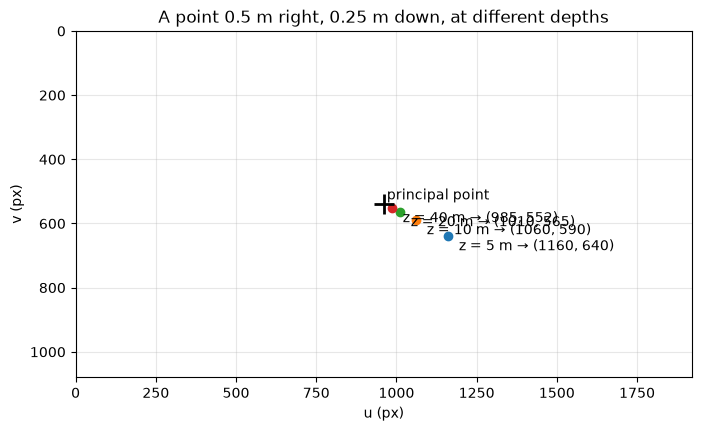

In [2]:
plt.figure(figsize=(8, 4.5))
for z in [5, 10, 20, 40]:
    u, v = cam_to_pixel((0.5, 0.25, z))
    plt.plot(u, v, "o")
    plt.annotate(f"z = {z} m → ({u:.0f}, {v:.0f})", (u, v), xytext=(8, -10), textcoords="offset points")
plt.plot(ox, oy, "k+", ms=14, mew=2)
plt.text(ox + 10, oy - 15, "principal point")
plt.xlim(0, W); plt.ylim(H, 0)           
plt.gca().set_aspect("equal")
plt.xlabel("u (px)"); plt.ylabel("v (px)")
plt.title("A point 0.5 m right, 0.25 m down, at different depths")
plt.grid(alpha=0.3)
plt.show()

### Worked example 2 · Converting homogeneous coordinates
(6, 4, 2) → (6/2, 4/2) = (3, 2). Also (3, 2, 1) → (3, 2) and (−3, −2, −1) → (3, 2): all the same
pixel.
In code: uv = x[:2] / x[2].

In [4]:
import numpy as np

def to_homogeneous(pts):
    pts = np.atleast_2d(np.asarray(pts, float))
    return np.hstack([pts, np.ones((len(pts),1))])

def from_homogeneous(pts_h):
    pts_h = np.atleast_2d(np.asarray(pts_h, float))
    return pts_h[:,:-1]/pts_h[:,-1:]

print(from_homogeneous([[6, 4, 2],
                        [3, 2, 1],
                        [-3, -2, -1]]))

[[3. 2.]
 [3. 2.]
 [3. 2.]]


Scaling doesn’t change the point

In [5]:
p = np.array([3.0, 2.0, 1.0])
for k in [1, 2, -1, 0.5, 100]:
    print(f"k = {k:>5}: {k * p} -> {from_homogeneous(k * p)[0]}")

k =     1: [3. 2. 1.] -> [3. 2.]
k =     2: [6. 4. 2.] -> [3. 2.]
k =    -1: [-3. -2. -1.] -> [3. 2.]
k =   0.5: [1.5 1.  0.5] -> [3. 2.]
k =   100: [300. 200. 100.] -> [3. 2.]


It works for 3D points too

In [6]:
print(to_homogeneous([[1, 2, 3]]))        # [[1. 2. 3. 1.]]
print(from_homogeneous([[2, 4, 6, 2]]))   # [[1. 2. 3.]]

[[1. 2. 3. 1.]]
[[1. 2. 3.]]
